# Homework MCMC — complete solution, 2026/2027

This notebook answers all four questions in Part 1 and all five questions in Part 2.
It combines mathematical justification, reproducible code, numerical checks, and interpretation,
following the submission instructions in the supplied slides.

**How to run:** keep this notebook, `mcmc_analysis.py`, `mcmc_sampler.py`, and
`sample_data.txt` together, then restart the Python kernel and run all cells.
All random streams have explicit seeds. Saved outputs include the figures and numerical results.
The supplied notebook and plotting script are preserved in `provided/` for reference.

**Conventions and assumptions.** An exponential *rate* is $\lambda$, so its density is
$f(t\mid\lambda)=\lambda e^{-\lambda t}$ for $t\geq0$, its mean lifetime is $1/\lambda$,
and its standard deviation is also $1/\lambda$. The file does not specify a time unit;
write it as $u$ and report rates in $u^{-1}$, without assuming seconds.
We assume independent, nonnegative, fully observed event times, with no detector dead time,
background, or upper acquisition cut. A physical selection or censoring mechanism would require
an explicitly modified likelihood. Sample sizes are treated as fixed.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import scipy
from scipy import stats, special, optimize
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import mcmc_analysis as ma

plt.rcParams.update({'text.usetex': False, 'font.family': 'DejaVu Sans',
                     'font.size': 11, 'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': .22, 'axes.spines.top': False,
                     'axes.spines.right': False})
OUT = Path('figures')
OUT.mkdir(exist_ok=True)
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print('Python', platform.python_version(), '| NumPy', np.__version__,
      '| SciPy', scipy.__version__, '| Matplotlib', matplotlib.__version__)

Python 3.14.7 | NumPy 2.5.3 | SciPy 1.18.1 | Matplotlib 3.11.1


## Part 1 — sensitivity studies
### 1. Generate 100 events, choose a likelihood, and plot the posterior

We generate $N=100$ times with known rate $\lambda_0=2\,u^{-1}$, so the simulation scale
argument is $1/\lambda_0=0.5\,u$. This is one random experiment, not a demand that the
estimate exactly equal the generating value.

For bins $[a_j,b_j)$ the probability is computed by integration,
\[
p_j(\lambda)=\int_{a_j}^{b_j}\lambda e^{-\lambda t}\,dt
=e^{-\lambda a_j}-e^{-\lambda b_j}.
\]
We include an overflow bin $[3,\infty)$, hence $\sum_jp_j=1$ and no observations are
discarded. The histogram has fixed total $N$, so its exact likelihood is **multinomial**:
\[
\log L_{\rm bin}(\lambda)=\mathrm{const}+\sum_j n_j\log p_j(\lambda).
\]
Equivalently, independent Poisson terms with $\mu_j=Np_j$ have the same dependence on
$\lambda$, since $\sum_j\mu_j=N$. This gives the familiar binned Poisson fit from the
practical sessions. We do not fit a Gaussian to sparse counts, nor approximate integrals
by density-at-bin-centre times width. Empty bins are retained; no pseudo-counts are added.

We use a proper Gamma prior in **shape–rate** convention,
$\lambda\sim\operatorname{Gamma}(\alpha=1,\beta=0.01\,u)$.
It is nearly flat over the likelihood-supported range; it is not a uniform prior in
$\log\lambda$. For comparison, the exact unbinned likelihood and posterior are
\[
L_{\rm raw}(\lambda)=\lambda^N e^{-\lambda S},\qquad
\lambda\mid t\sim\operatorname{Gamma}(N+\alpha,S+\beta),\qquad S=\sum_i t_i.
\]
The unbinned result is the information-preserving reference, while the binned result
answers the binning questions. The Gamma posterior validates the scale and uncertainty;
numerical quadrature separately validates MCMC for its actual binned target.

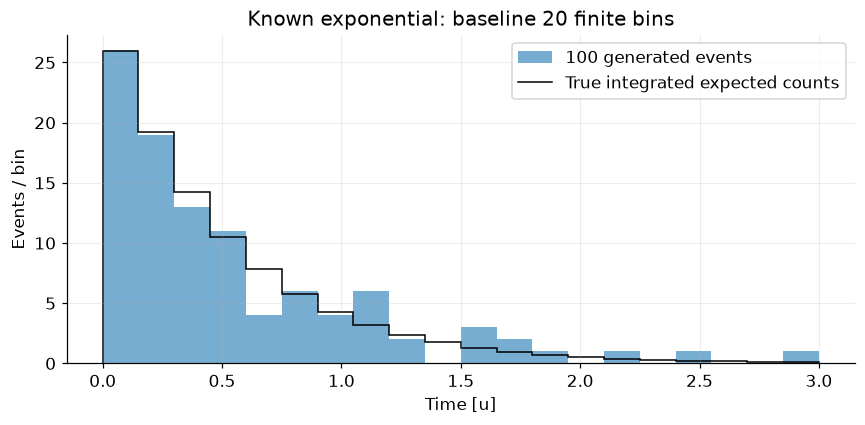

N = 100 | sample mean = 0.5575096662249142 | unbinned MLE = 1.7936908731490468
Overflow events = 0


In [2]:
LAMBDA_TRUE, ALPHA, BETA = 2., 1., .01
sample1 = np.random.default_rng(20261023).exponential(1 / LAMBDA_TRUE, 100)
HORIZON = 3.
edge_sets = {f'linear {k}': np.r_[np.linspace(0, HORIZON, k + 1), np.inf]
             for k in [2, 20, 200]}
edge_sets['log 20'] = np.r_[0., np.geomspace(.003, HORIZON, 20), np.inf]
reference = stats.gamma(a=len(sample1) + ALPHA, scale=1 / (sample1.sum() + BETA))
rate_grid = np.linspace(.001, 8., 8000)
grid_results = {name: ma.grid_posterior(sample1, edges, rate_grid, ALPHA, BETA)
                for name, edges in edge_sets.items()}

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sample1, bins=edge_sets['linear 20'][:-1], density=False,
        alpha=.6, label='100 generated events')
edges = edge_sets['linear 20']
expected = len(sample1) * np.exp(ma.exp_logprob(LAMBDA_TRUE, edges))
ax.stairs(expected[:-1], edges[:-1], color='black', label='True integrated expected counts')
ax.set(xlabel='Time [u]', ylabel='Events / bin', title='Known exponential: baseline 20 finite bins')
ax.legend()
finish(fig, '01_generated_data')
print('N =', len(sample1), '| sample mean =', sample1.mean(),
      '| unbinned MLE =', len(sample1) / sample1.sum())
print('Overflow events =', np.count_nonzero(sample1 >= HORIZON))

**Sampler implementation and checks.** The supplied `mcmc_sampler.py` contains the generic
class but not `mcmc_sampler_exp_model`; the latter is implemented in `mcmc_analysis.py`
as a subclass that reuses the supplied chain loop. Normal proposals are made once and
out-of-support proposals are rejected. Repeatedly drawing until a proposal is inside
the bounds would introduce a position-dependent normalization and require a Hastings
correction. Acceptance uses $\log U<\log\pi(\lambda')-\log\pi(\lambda)$ to avoid overflow.
The supplied plotting module forces external LaTeX and imports packages that are not
needed here; portable Matplotlib plots replace those routines.

For each binning we run four independently seeded chains, discard 3,000 warm-up steps,
and retain 12,000 steps per chain. Starting rates are deliberately separated. Proposal
width is 2.4 times the quadrature posterior SD, fixed throughout sampling; this is a
one-dimensional validation exercise where quadrature is available. All retained draws
are used, with no thinning for inference.

We inspect traces and autocorrelations and compute rank-normalized, folded split
$\widehat R$, bulk/tail effective sample size (ESS), and the Monte Carlo standard error
(MCSE) of each posterior mean. The diagnostics follow the definitions in the
[Stan reference manual](https://mc-stan.org/docs/reference-manual/analysis.html).
We require $\widehat R<1.01$ and both ESS values above 400. These are diagnostic checks,
not a proof of convergence. Posterior SD describes uncertainty about the physical rate;
MCSE describes numerical uncertainty from a finite chain and should be much smaller.

Binning,Acceptance,R-hat,Bulk ESS,Tail ESS,MCSE(mean)
linear 2,0.435,1.0003,10921,11106,0.00211
linear 20,0.442,1.0002,11357,12176,0.00173
linear 200,0.438,1.0003,10862,11610,0.00172
log 20,0.441,1.0005,11554,12460,0.00168


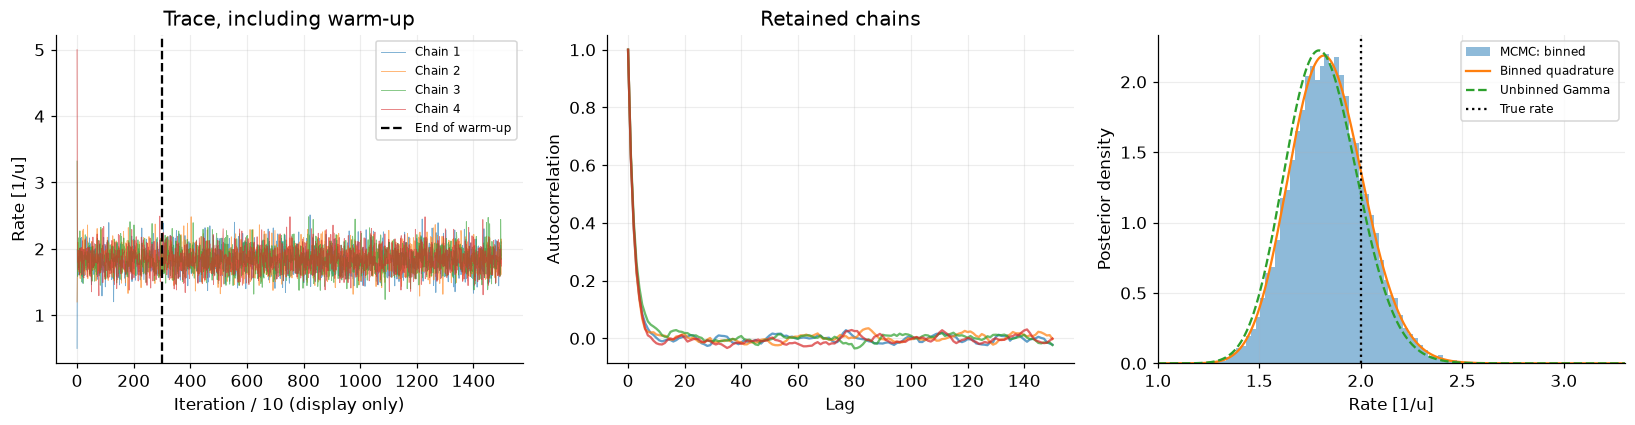

The unbinned posterior mean is **1.8113** with SD **0.1802** and a 95% equal-tail credible interval **[1.4753, 2.1812]** in inverse time units. The true rate 2.0 lies in this interval. A posterior is conditional on this particular random sample; agreement with the known value is assessed relative to its uncertainty.

In [3]:
chains1, diagnostics1, accept1 = {}, {}, {}
full_baseline = None
for case, (name, edges) in enumerate(edge_sets.items()):
    post, accepts, fulls = [], [], []
    for c, start in enumerate([.5, 1.2, 3.5, 5.]):
        sampler = ma.mcmc_sampler_exp_model(sample1, edges, start,
                    2.4 * grid_results[name]['sd'], seed=1000 + 10 * case + c,
                    alpha=ALPHA, beta=BETA)
        draws, acceptance, full = sampler.sample(draws=12000, burn=3000)
        post.append(draws)
        accepts.append(acceptance)
        fulls.append(full)
    chains1[name] = np.array(post)
    accept1[name] = np.mean(accepts)
    diagnostics1[name] = ma.diagnostics(chains1[name])[0]
    if name == 'linear 20':
        full_baseline = np.array(fulls)

ma.show_table([(name, accept1[name], d['rhat'], d['bulk_ess'], d['tail_ess'], d['mcse'])
              for name, d in diagnostics1.items()],
             ['Binning', 'Acceptance', 'R-hat', 'Bulk ESS', 'Tail ESS', 'MCSE(mean)'],
             [None, '.3f', '.4f', '.0f', '.0f', '.5f'])
for name, d in diagnostics1.items():
    assert d['rhat'] < 1.01 and min(d['bulk_ess'], d['tail_ess']) > 400
    assert abs(chains1[name].mean() - grid_results[name]['mean']) < 5*d['mcse'] + 1e-4

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for c in range(4):
    axes[0].plot(full_baseline[c, ::10, 0], alpha=.6, lw=.6, label=f'Chain {c+1}')
    axes[1].plot(ma.acf(chains1['linear 20'][c, :, 0]), alpha=.7)
axes[0].axvline(300, color='black', ls='--', label='End of warm-up')
axes[0].set(xlabel='Iteration / 10 (display only)', ylabel='Rate [1/u]', title='Trace, including warm-up')
axes[0].legend(fontsize=8)
axes[1].set(xlabel='Lag', ylabel='Autocorrelation', title='Retained chains')
axes[2].hist(chains1['linear 20'].ravel(), bins=65, density=True, alpha=.5, label='MCMC: binned')
axes[2].plot(rate_grid, grid_results['linear 20']['pdf'], label='Binned quadrature')
axes[2].plot(rate_grid, reference.pdf(rate_grid), ls='--', label='Unbinned Gamma')
axes[2].axvline(LAMBDA_TRUE, color='black', ls=':', label='True rate')
axes[2].set(xlim=(1., 3.3), xlabel='Rate [1/u]', ylabel='Posterior density')
axes[2].legend(fontsize=8)
finish(fig, '02_baseline_posterior_diagnostics')

lo, hi = reference.ppf([.025, .975])
display(Markdown(f'The unbinned posterior mean is **{reference.mean():.4f}** with SD '
                 f'**{reference.std():.4f}** and a 95% equal-tail credible interval '
                 f'**[{lo:.4f}, {hi:.4f}]** in inverse time units. '
                 f'The true rate {LAMBDA_TRUE:.1f} '
                 f'{"lies" if lo <= LAMBDA_TRUE <= hi else "does not lie"} in this interval. '
                 'A posterior is conditional on this particular random sample; agreement with '
                 'the known value is assessed relative to its uncertainty.'))

### 2. Multiply and divide the number of bins by ten

The baseline has 20 equal-width finite bins on $[0,3]$; compare 2 and 200 bins, always
with the same overflow bin, same events, likelihood, and prior. We quantify **sensitivity**
by posterior SD and 95% credible interval width (smaller is better).

Coarse bins erase within-bin timing information. Finer bins approach the unbinned
likelihood, even when many counts are zero: a Poisson/multinomial likelihood remains valid
for sparse counts. More bins cannot create new event information. For these nested
partitions the expected Fisher information cannot decrease when a bin is split, although
a realized posterior width need not decrease monotonically for every possible dataset.
Numerical quadrature provides the comparison without confusing binning effects with
Monte Carlo noise.

Method,Mean,SD,95% low,95% high,SD / unbinned SD
linear 2,1.7030,0.2194,1.3128,2.1715,1.2172
linear 20,1.8359,0.1833,1.4945,2.2122,1.0168
linear 200,1.8132,0.1804,1.4769,2.1836,1.0011
log 20,1.8005,0.1812,1.4633,2.1728,1.0052
unbinned,1.8113,0.1802,1.4753,2.1812,1.0000


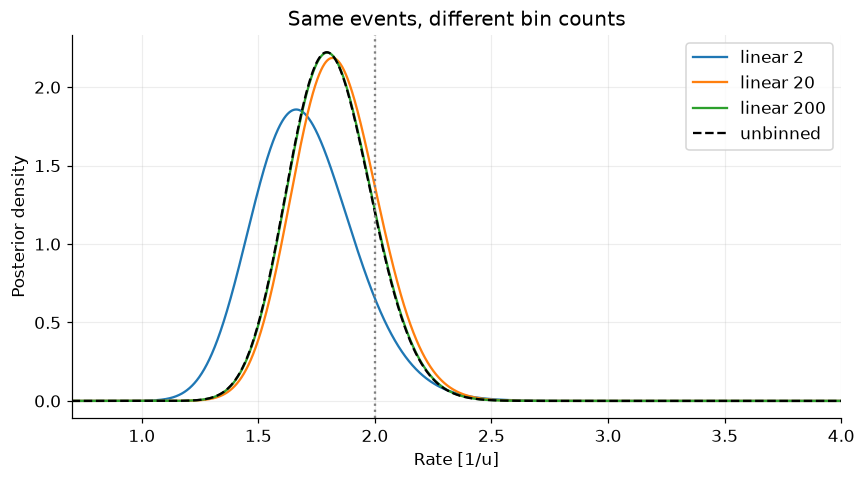

With 2 bins the SD is 1.22 times the unbinned SD. With 200 bins the ratio is 1.0011. The coarse histogram loses measurable timing information; fine binning recovers nearly all the information in this sample.

In [4]:
binning_rows = []
for name in ['linear 2', 'linear 20', 'linear 200', 'log 20']:
    g = grid_results[name]
    binning_rows.append((name, g['mean'], g['sd'], g['lo'], g['hi'], g['sd']/reference.std()))
binning_rows.append(('unbinned', reference.mean(), reference.std(),
                     *reference.ppf([.025, .975]), 1.))
ma.show_table(binning_rows, ['Method', 'Mean', 'SD', '95% low', '95% high', 'SD / unbinned SD'],
              [None] + ['.4f']*5)

fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ['linear 2', 'linear 20', 'linear 200']:
    ax.plot(rate_grid, grid_results[name]['pdf'], label=name)
ax.plot(rate_grid, reference.pdf(rate_grid), color='black', ls='--', label='unbinned')
ax.axvline(LAMBDA_TRUE, color='gray', ls=':')
ax.set(xlim=(.7, 4), xlabel='Rate [1/u]', ylabel='Posterior density', title='Same events, different bin counts')
ax.legend()
finish(fig, '03_linear_binning_comparison')
display(Markdown(f"With 2 bins the SD is {grid_results['linear 2']['sd']/reference.std():.2f} "
                 f"times the unbinned SD. With 200 bins the ratio is "
                 f"{grid_results['linear 200']['sd']/reference.std():.4f}. "
                 'The coarse histogram loses measurable timing information; fine binning '
                 'recovers nearly all the information in this sample.'))

### 3. Logarithmic binning

Use 20 finite bins: an initial $[0,0.003)$ bin and geometrically spaced edges from
$0.003$ to $3$, followed by overflow. A logarithmic axis cannot include zero, but the
likelihood must still include that first bin. With unequal widths, density plots show
$n_j/(N\Delta t_j)$, not counts alone. The fit still uses integer counts and integrated
probabilities, not normalized histogram heights.

Logarithmic binning gives high time resolution near zero and coarser resolution later.
For one exponential, time resolution around its characteristic scale matters more than
resolving arbitrarily tiny times. Thus log bins are not automatically better than linear
bins at equal bin count; these two partitions are not nested. Their main advantage in
Part 2 is representing two very different lifetimes efficiently.

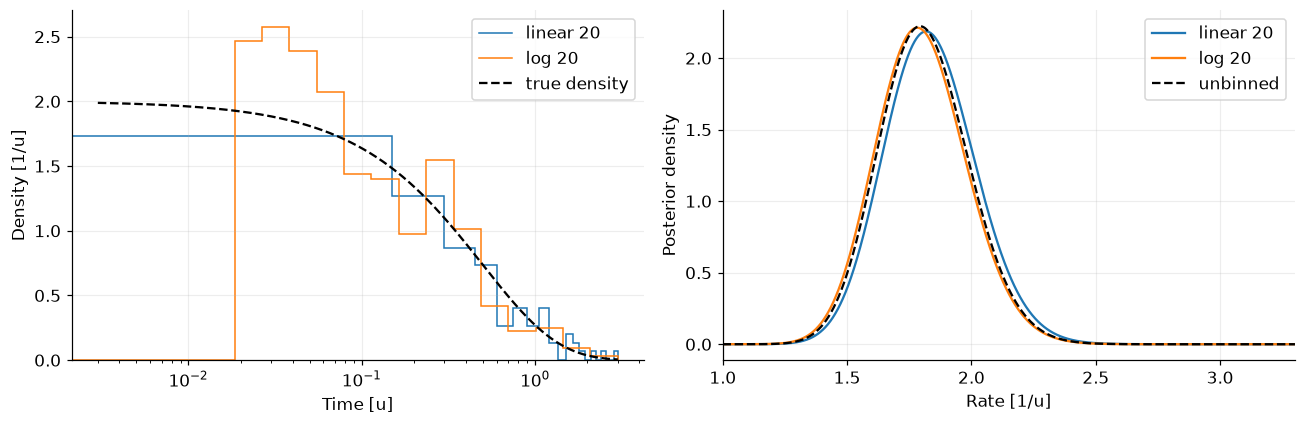

The log-bin SD is **0.1812**, versus **0.1833** for 20 linear bins (ratio 0.989). This difference reflects the placement of the edges, not the axis scale used to draw the plot.

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ['linear 20', 'log 20']:
    edges = edge_sets[name]
    counts = np.histogram(sample1, edges)[0]
    density = counts[:-1] / (len(sample1)*np.diff(edges[:-1]))
    axes[0].stairs(density, edges[:-1], label=name)
    axes[1].plot(rate_grid, grid_results[name]['pdf'], label=name)
tt = np.geomspace(.003, 3, 400)
axes[0].plot(tt, LAMBDA_TRUE*np.exp(-LAMBDA_TRUE*tt), 'k--', label='true density')
axes[0].set(xscale='log', xlabel='Time [u]', ylabel='Density [1/u]')
axes[1].plot(rate_grid, reference.pdf(rate_grid), 'k--', label='unbinned')
axes[1].set(xlim=(1, 3.3), xlabel='Rate [1/u]', ylabel='Posterior density')
for ax in axes:
    ax.legend()
finish(fig, '04_log_binning_comparison')
display(Markdown(f"The log-bin SD is **{grid_results['log 20']['sd']:.4f}**, versus "
                 f"**{grid_results['linear 20']['sd']:.4f}** for 20 linear bins "
                 f"(ratio {grid_results['log 20']['sd']/grid_results['linear 20']['sd']:.3f}). "
                 'This difference reflects the placement of the edges, not the axis scale used to draw the plot.'))

### 4. Resolution versus number of events

For the unbinned likelihood, the Fisher information is $I_N(\lambda)=N/\lambda^2$;
therefore the large-sample resolution is $\sigma_\lambda\simeq\lambda/\sqrt N$.
For a single dataset the exact posterior SD is
$\sqrt{N+\alpha}/(S+\beta)$. For repeated independent datasets the MLE
$\widehat\lambda=N/S$ has exact standard deviation
\[
\operatorname{SD}(\widehat\lambda)=
\frac{\lambda_0N}{(N-1)\sqrt{N-2}},\quad N>2.
\]
These are different concepts: posterior uncertainty for one dataset versus the sampling
variability of the estimator. We show both at the requested sample sizes.

First, prefixes of one 20,000-event simulation give a conditional posterior curve.
Second, 1,000 independent pseudo-experiments per size estimate sampling SD and interval
coverage. Drawing $S\sim\operatorname{Gamma}(N,\text{rate}=\lambda_0)$ is exactly equivalent
to summing $N$ independent exponential times, and is much cheaper. A fixed 20-bin
quadrature result additionally checks that the rate of improvement survives binning.
Exact posteriors suffice here; rerunning MCMC would add numerical noise to a known answer.

N,Posterior SD,20-bin SD,Repeated-MLE SD,Exact MLE SD,95% coverage
100,0.17263,0.17438,0.20908,0.20407,0.942
1000,0.05903,0.05925,0.06241,0.06337,0.947
2000,0.04309,0.04321,0.04564,0.04477,0.946
5000,0.02761,0.02777,0.02744,0.02830,0.956
10000,0.01989,0.02000,0.02030,0.02000,0.945
20000,0.01407,0.01414,0.01415,0.01414,0.953


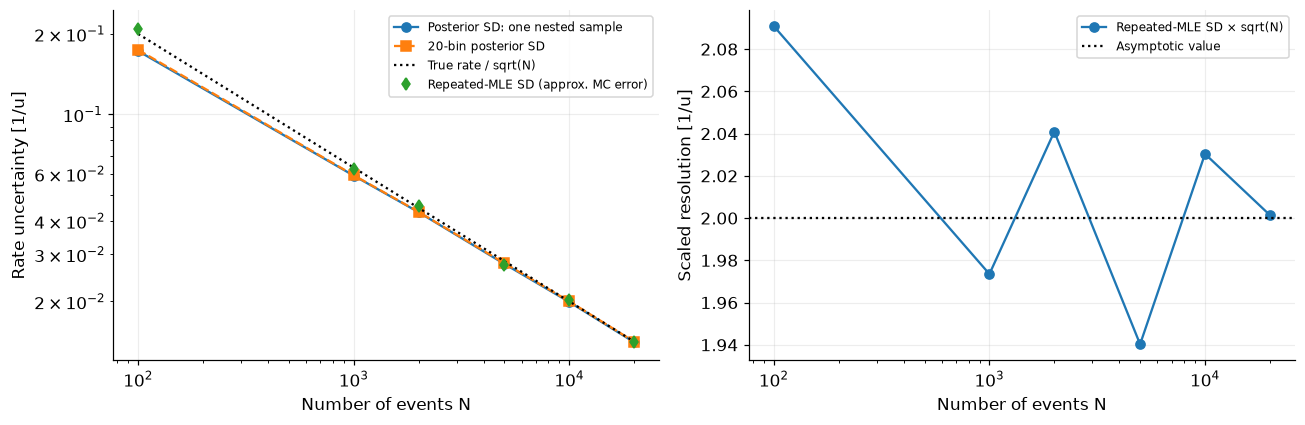

The fitted log–log slope of the repeated-experiment SD is **-0.507**, consistent with the expected −0.5. Increasing N from 100 to 20,000 should improve asymptotic resolution by a factor of sqrt(200) ≈ **14.14**. The approximate relative Monte Carlo error on an empirical SD from 1,000 replicates is 2.2%; coverage near 0.95 fluctuates by about 0.007. These repetitions quantify sampling variation, not additional information about the one original dataset.

In [6]:
sizes = np.array([100, 1000, 2000, 5000, 10000, 20000])
resolution_rng = np.random.default_rng(20261024)
large_sample = resolution_rng.exponential(1/LAMBDA_TRUE, sizes[-1])
R = 1000
posterior_sd, binned_sd, sampling_sd, coverages = [], [], [], []
for n in sizes:
    x = large_sample[:n]
    exact = stats.gamma(a=n+ALPHA, scale=1/(x.sum()+BETA))
    posterior_sd.append(exact.std())
    local_grid = np.linspace(max(.0001, exact.mean()-9*exact.std()),
                             exact.mean()+10*exact.std(), 2500)
    binned_sd.append(ma.grid_posterior(x, edge_sets['linear 20'], local_grid)['sd'])
    sums = resolution_rng.gamma(shape=n, scale=1/LAMBDA_TRUE, size=R)
    sampling_sd.append(np.std(n/sums, ddof=1))
    ci = stats.gamma.ppf(np.array([.025, .975])[:, None],
                         a=n+ALPHA, scale=1/(sums+BETA))
    coverages.append(np.mean((ci[0] <= LAMBDA_TRUE) & (LAMBDA_TRUE <= ci[1])))
posterior_sd, binned_sd, sampling_sd = map(np.array, (posterior_sd, binned_sd, sampling_sd))
exact_sampling_sd = LAMBDA_TRUE*sizes/((sizes-1)*np.sqrt(sizes-2))
slope = np.polyfit(np.log(sizes), np.log(sampling_sd), 1)[0]
ma.show_table(list(zip(sizes, posterior_sd, binned_sd, sampling_sd, exact_sampling_sd, coverages)),
             ['N', 'Posterior SD', '20-bin SD', 'Repeated-MLE SD', 'Exact MLE SD', '95% coverage'],
             ['d', '.5f', '.5f', '.5f', '.5f', '.3f'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].loglog(sizes, posterior_sd, 'o-', label='Posterior SD: one nested sample')
axes[0].loglog(sizes, binned_sd, 's--', label='20-bin posterior SD')
axes[0].errorbar(sizes, sampling_sd, yerr=sampling_sd/np.sqrt(2*(R-1)),
                 fmt='d', label='Repeated-MLE SD (approx. MC error)')
axes[0].loglog(sizes, LAMBDA_TRUE/np.sqrt(sizes), 'k:', label='True rate / sqrt(N)')
axes[0].set(xlabel='Number of events N', ylabel='Rate uncertainty [1/u]')
axes[0].legend(fontsize=8)
axes[1].semilogx(sizes, sampling_sd*np.sqrt(sizes), 'o-', label='Repeated-MLE SD × sqrt(N)')
axes[1].axhline(LAMBDA_TRUE, color='black', ls=':', label='Asymptotic value')
axes[1].set(xlabel='Number of events N', ylabel='Scaled resolution [1/u]')
axes[1].legend(fontsize=8)
finish(fig, '05_resolution_vs_statistics')
display(Markdown(f'The fitted log–log slope of the repeated-experiment SD is **{slope:.3f}**, '
                 'consistent with the expected −0.5. Increasing N from 100 to 20,000 '
                 'should improve asymptotic resolution by a factor of sqrt(200) ≈ **14.14**. '
                 'The approximate relative Monte Carlo error on an empirical SD from 1,000 '
                 'replicates is 2.2%; coverage near 0.95 fluctuates by about 0.007. '
                 'These repetitions quantify sampling variation, not additional information '
                 'about the one original dataset.'))

## Part 2 — two-exponential data
### 1. Represent the data and justify the binning

The model is a **mixture**, because each observed event belongs to one of two populations:
\[
f(t)=w\lambda_s e^{-\lambda_s t}+(1-w)\lambda_f e^{-\lambda_f t},\qquad
0<\lambda_s<\lambda_f,\quad 0<w<1.
\]
Here $w$ is the **slow-component event fraction**, not its density amplitude at $t=0$.
The ordering fixes the otherwise interchangeable labels. A sum of two exponential
waiting times would be a different probability model and is not used here.

The log histogram uses an initial $[0,10^{-6})$ bin and 60 geometric edges between
$10^{-6}$ and $0.1\,u$, plus overflow. This allocates bins to both timescales.
The plots divide counts by $N\Delta t$, so unequal widths cannot create a false density
trend. The first and overflow bins are included in every fit even where the axes do not
display them. The linear early-time panel complements the wide-range logarithmic view.

Quantity,Value
N,3300
Minimum [u],2.7079894043808565e-08
Median [u],0.002950229720480252
Mean [u],0.006523680887741343
Maximum [u],0.06386399282292053


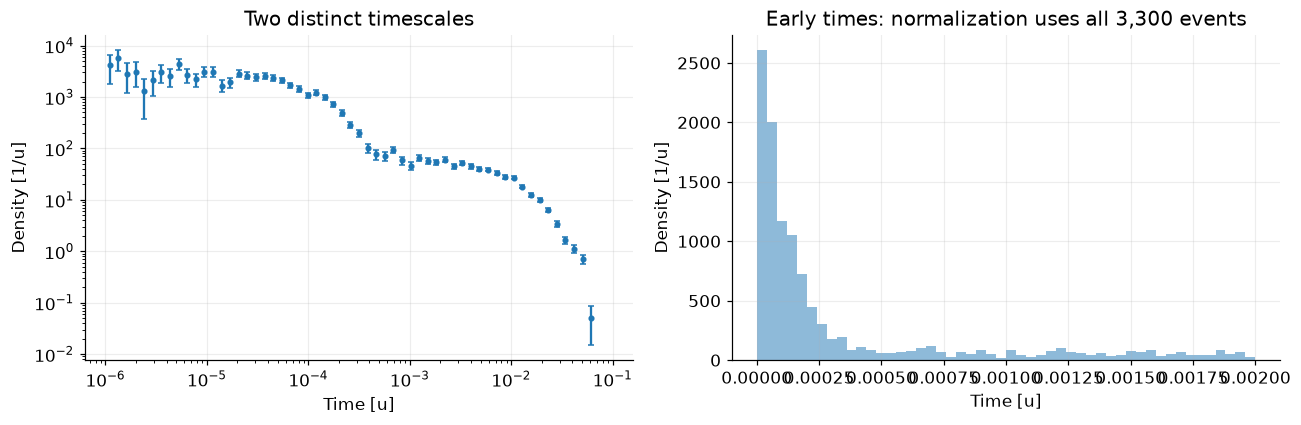

First-bin count: 14 | overflow: 0


In [7]:
sample2 = np.loadtxt('sample_data.txt')
assert sample2.ndim == 1 and np.all(np.isfinite(sample2)) and np.all(sample2 >= 0)
N2 = len(sample2)
mix_edges = np.r_[0., np.geomspace(1e-6, .1, 60), np.inf]
mix_counts = np.histogram(sample2, mix_edges)[0]
assert mix_counts.sum() == N2
ma.show_table([('N', N2), ('Minimum [u]', sample2.min()), ('Median [u]', np.median(sample2)),
              ('Mean [u]', sample2.mean()), ('Maximum [u]', sample2.max())], ['Quantity', 'Value'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
finite = mix_edges[:-1]
centers = np.sqrt(finite[1:-1]*finite[2:])
dens = mix_counts[1:-1]/(N2*np.diff(finite)[1:])
err = np.sqrt(mix_counts[1:-1])/(N2*np.diff(finite)[1:])
axes[0].errorbar(centers, dens, yerr=err, fmt='.', capsize=2)
axes[0].set(xscale='log', yscale='log', xlabel='Time [u]', ylabel='Density [1/u]', title='Two distinct timescales')
early_edges = np.linspace(0, .002, 51)
early_counts = np.histogram(sample2, early_edges)[0]
axes[1].stairs(early_counts/(N2*np.diff(early_edges)), early_edges, fill=True, alpha=.5)
axes[1].set(xlabel='Time [u]', ylabel='Density [1/u]', title='Early times: normalization uses all 3,300 events')
finish(fig, '06_mixture_data')
print('First-bin count:', mix_counts[0], '| overflow:', mix_counts[-1])

### 2. Choose a time cut for the slow component

After a cut $t>c$, an exponential's excess $y=t-c$ is again exponential. Therefore
the tail MLE is $\widehat\lambda_s(c)=n_c/\sum_{t_i>c}(t_i-c)$, with approximate standard
error $\widehat\lambda_s/\sqrt{n_c}$. Using $n_c/\sum t_i$ would ignore truncation and
bias the rate downwards.

We scan cutoffs and choose **$c=0.001\,u$** in the stable region, balancing removal of
fast events with retention of the slow population. A plateau is evidence, not proof,
that fast contamination has become negligible. We quantify the remaining contamination
after the global fit. Cut-scan points are strongly correlated because they reuse events;
the displayed errors treat each cut as fixed and do not include data-driven selection.

Cut [u],Retained events,Tail MLE [1/u],Approx. SE [1/u]
0,3300,153.288,2.668
0.0002,2302,109.650,2.285
0.0004,2142,104.212,2.252
0.0006,2091,103.867,2.271
0.0008,2038,103.350,2.289
0.001,2002,103.645,2.316
0.0015,1903,103.763,2.379
0.002,1810,103.951,2.443
0.003,1640,104.513,2.581
0.005,1339,105.178,2.874


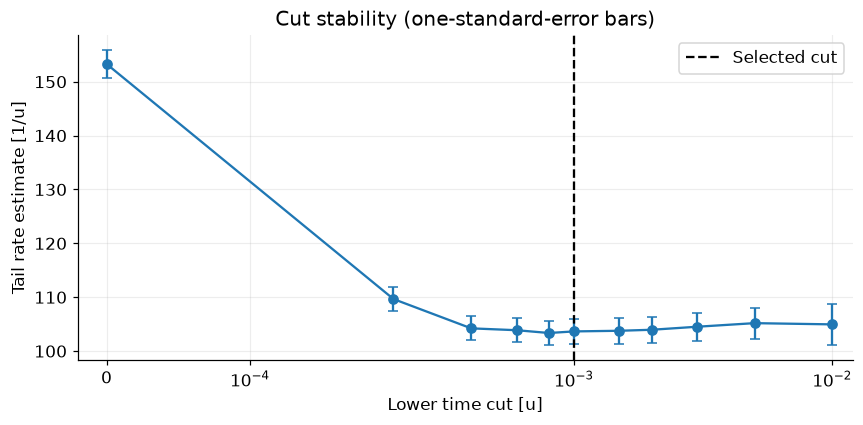

In [8]:
cuts = np.array([0, .0002, .0004, .0006, .0008, .001, .0015, .002, .003, .005, .01])
cut_rows = []
for cut in cuts:
    y = sample2[sample2 > cut] - cut
    rate = len(y)/y.sum()
    cut_rows.append((cut, len(y), rate, rate/np.sqrt(len(y))))
ma.show_table(cut_rows, ['Cut [u]', 'Retained events', 'Tail MLE [1/u]', 'Approx. SE [1/u]'],
             ['.4g', 'd', '.3f', '.3f'])
CUT = .001
tail = sample2[sample2 > CUT] - CUT
slow_mle = len(tail)/tail.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(cuts, [r[2] for r in cut_rows], yerr=[r[3] for r in cut_rows], fmt='o-', capsize=3)
ax.axvline(CUT, color='black', ls='--', label='Selected cut')
ax.set(xscale='symlog', xlim=(-.00002, .012), xlabel='Lower time cut [u]',
       ylabel='Tail rate estimate [1/u]', title='Cut stability (one-standard-error bars)')
ax.set_xscale('symlog', linthresh=.0002)
ax.legend()
finish(fig, '07_cut_stability')

### 3. Fit the slow decay rate after the cut

The normalized conditional density is
\[
f(t\mid t>c,\lambda_s)=\lambda_s e^{-\lambda_s(t-c)}\mathbf 1_{t>c},
\quad \ell_c=n_c\log\lambda_s-\lambda_s S_c,\quad S_c=\sum(t_i-c).
\]
This is an unbinned maximum-likelihood fit with an analytic optimum. Since
$2\lambda_s S_c\sim\chi^2_{2n_c}$ for a pure exponential tail, an exact conditional 95%
confidence interval is
$[\chi^2_{2n_c,.025}/(2S_c),\chi^2_{2n_c,.975}/(2S_c)]$.
Its interpretation assumes the cut was fixed and the residual fast fraction is negligible.

The cut retains **2002 / 3300** events. The slow-rate MLE is **103.645 ± 2.316 u⁻¹** (approximate 1-SE), with conditional 95% confidence interval **[99.154, 108.234] u⁻¹**. The corresponding lifetime is **0.009648 u**.

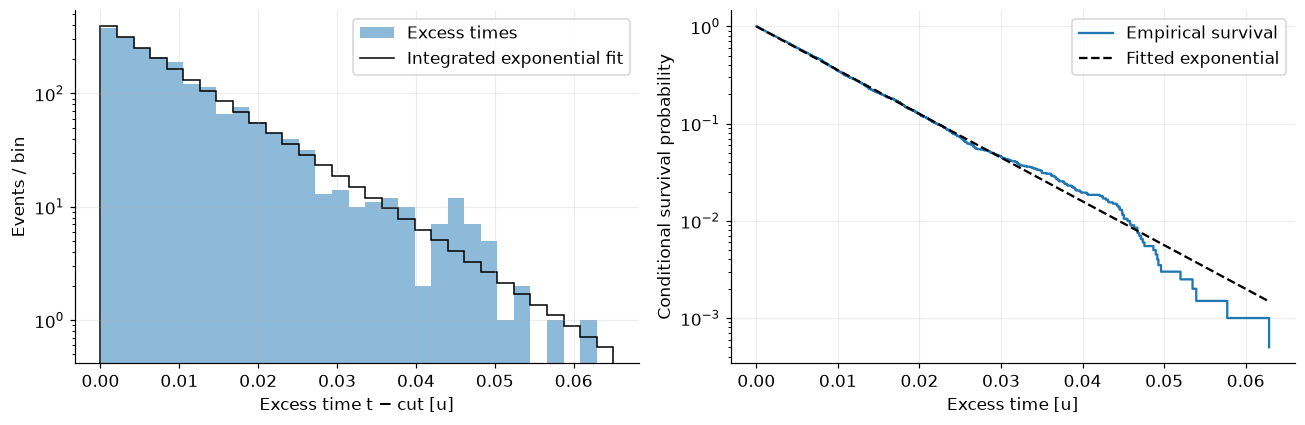

In [9]:
tail_ci = stats.chi2.ppf([.025, .975], 2*len(tail))/(2*tail.sum())
tail_se = slow_mle/np.sqrt(len(tail))
tail_numeric = optimize.minimize_scalar(lambda rate: -len(tail)*np.log(rate)+rate*tail.sum(),
                                        bounds=(1, 1000), method='bounded')
assert tail_numeric.success and np.isclose(tail_numeric.x, slow_mle, rtol=1e-5)
display(Markdown(f'The cut retains **{len(tail)} / {N2}** events. The slow-rate MLE is '
                 f'**{slow_mle:.3f} ± {tail_se:.3f} u⁻¹** (approximate 1-SE), with conditional '
                 f'95% confidence interval **[{tail_ci[0]:.3f}, {tail_ci[1]:.3f}] u⁻¹**. '
                 f'The corresponding lifetime is **{1/slow_mle:.6f} u**.'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tail_edges = np.linspace(0, .065, 32)
tc = np.histogram(tail, tail_edges)[0]
axes[0].stairs(tc, tail_edges, fill=True, alpha=.5, label='Excess times')
axes[0].stairs(len(tail)*np.exp(ma.exp_logprob(slow_mle, tail_edges)), tail_edges,
               color='black', label='Integrated exponential fit')
axes[0].set(yscale='log', xlabel='Excess time t − cut [u]', ylabel='Events / bin')
axes[0].legend()
ordered_tail = np.sort(tail)
survival = (len(tail)-np.arange(len(tail)))/len(tail)
axes[1].step(ordered_tail, survival, where='post', label='Empirical survival')
axes[1].plot(ordered_tail, np.exp(-slow_mle*ordered_tail), 'k--', label='Fitted exponential')
axes[1].set(yscale='log', xlabel='Excess time [u]', ylabel='Conditional survival probability')
axes[1].legend()
finish(fig, '08_tail_fit')

### 4. Extract the fast exponential

A useful initial estimate extrapolates the slow tail back to zero. Neglecting fast
survivors above the cut, $P(t>c)\simeq w e^{-\lambda_s c}$, hence
$\widehat w\simeq(n_c/N)e^{\widehat\lambda_s c}$.
One could subtract the predicted slow counts in early bins, but the residual counts
would be noisy, possibly negative, and correlated with the fitted slow component.

Instead, keep the tail-derived $\widehat\lambda_s,\widehat w$ fixed initially and maximize
the **mixture likelihood** over $\lambda_f>\lambda_s$, using all times. This extracts the
fast component while allowing slow events near zero. It is an initialization, not the
final uncertainty calculation: fixing two estimated parameters understates uncertainty.
The next step jointly fits all three parameters and propagates their correlations.

In [10]:
w_initial = len(tail)/N2 * np.exp(slow_mle*CUT)
assert 0 < w_initial < 1
def fast_initial_nll(logfast):
    fast = np.exp(logfast)
    return -np.logaddexp(np.log(w_initial*slow_mle)-slow_mle*sample2,
                         np.log((1-w_initial)*fast)-fast*sample2).sum()
fast_fit = optimize.minimize_scalar(fast_initial_nll,
           bounds=(np.log(slow_mle*1.01), np.log(1e6)), method='bounded')
assert fast_fit.success
fast_initial = np.exp(fast_fit.x)
display(Markdown(f'The tail extrapolation gives a slow fraction **{w_initial:.4f}** '
                 f'and a preliminary fast rate **{fast_initial:.1f} u⁻¹**, '
                 f'or lifetime **{1/fast_initial:.7f} u**. '
                 'These preliminary values initialize the joint fit below.'))

The tail extrapolation gives a slow fraction **0.6729** and a preliminary fast rate **9909.3 u⁻¹**, or lifetime **0.0001009 u**. These preliminary values initialize the joint fit below.

### 5. Global fit of the two exponentials

Use the logarithmic bins introduced in Question 1. Their exact probabilities are
\[
p_j=w(e^{-\lambda_sa_j}-e^{-\lambda_sb_j})
 +(1-w)(e^{-\lambda_fa_j}-e^{-\lambda_fb_j}),
\quad \ell=\sum_jn_j\log p_j+\mathrm{const}.
\]
All events, including the tail used above, enter **once**. We do not multiply by a
separate tail likelihood, which would double-count the same observations.
Multiple optimizer starts check for competing local solutions. The primary fit is
binned; an unbinned fit and a fine linear histogram are independent numerical cross-checks
of binning effects. For the latter, 1,000 finite bins on $[0,0.1]$ give width $10^{-4}\,u$,
small enough to resolve the fast lifetime. Its many empty bins are valid likelihood terms.

For Bayesian uncertainty, choose independent log-uniform rate priors on
$[1,10^6]\,u^{-1}$, conditioned on $\lambda_s<\lambda_f$, and $w\sim\mathrm{Uniform}(0,1)$.
These are proper, broad, scale-based priors whose boundaries are far from the estimates;
they are different from Part 1's prior and are specified explicitly.
We sample $z=(\log\lambda_s,\log\lambda_f,\operatorname{logit}w)$.
The rate Jacobians cancel the $1/(\lambda_s\lambda_f)$ prior, but the logit Jacobian
remains, giving $\log\pi(z\mid n)=\ell(z)+\log w+\log(1-w)+\mathrm{const}$ within the bounds.
Omitting this term would change the prior on $w$.

A numerical Hessian at the likelihood optimum supplies a fixed Gaussian proposal
covariance $(2.38^2/3)H^{-1}$ in transformed coordinates. Four chains start at separated
points, discard 4,000 steps each, and retain 20,000 steps each. The likelihood Hessian
also gives local approximate frequentist standard errors; MCMC gives the reported
posterior intervals without a Gaussian posterior assumption.

In [11]:
z_initial = np.array([np.log(slow_mle), np.log(fast_initial), special.logit(w_initial)])
fit_log = ma.fit_mixture(sample2, mix_edges, start=z_initial)
fit_raw = ma.fit_mixture(sample2, start=z_initial)
linear_edges2 = np.r_[np.linspace(0, .1, 1001), np.inf]
fit_linear = ma.fit_mixture(sample2, linear_edges2, start=z_initial)
fit_cases = [('log bins (primary)', fit_log, mix_edges),
             ('linear 1000', fit_linear, linear_edges2), ('unbinned', fit_raw, None)]
fit_rows = []
for name, fit, edges in fit_cases:
    counts = None if edges is None else np.histogram(sample2, edges)[0]
    objective = lambda z: ma.mixture_nll(z, counts, edges, sample2 if edges is None else None)
    H = ma.hessian(objective, fit.x)
    assert np.all(np.linalg.eigvalsh(H) > 0)
    cov = np.linalg.inv(H)
    s, f, w = ma.decode(fit.x)
    errors = np.sqrt(np.diag(cov))*np.array([s, f, w*(1-w)])
    fit_rows.append((name, s, errors[0], f, errors[1], w, errors[2]))
    if edges is mix_edges:
        cov_log = cov
ma.show_table(fit_rows, ['Fit', 'Slow MLE', 'SE(slow)', 'Fast MLE', 'SE(fast)', 'Slow fraction', 'SE(fraction)'],
              [None, '.3f', '.3f', '.1f', '.1f', '.5f', '.5f'])
print('Primary optimizer:', fit_log.message)
print('Unbinned optimizer:', fit_raw.message)

target_mix = lambda z: ma.mixture_logposterior(z, mix_counts, mix_edges)
mix_z, mix_accept, mix_full = [], [], []
offsets = np.array([[-4, -3, -3], [4, 3, 3], [-3, 4, 2], [3, -4, -2]])
for c in range(4):
    start = fit_log.x + np.linalg.cholesky(cov_log) @ offsets[c]
    sampler = ma.SafeSampler(target_mix, start, cov_log*(2.38**2/3), seed=2200+c)
    draws, acceptance, full = sampler.sample(draws=20000, burn=4000)
    mix_z.append(draws)
    mix_accept.append(acceptance)
    mix_full.append(ma.decode(full))
mix_z = np.array(mix_z)
mix_chains = ma.decode(mix_z)
mix_flat = mix_chains.reshape(-1, 3)
mix_diag = ma.diagnostics(mix_chains)
names2 = ['Slow rate [1/u]', 'Fast rate [1/u]', 'Slow fraction']
ma.show_table([(name, d['rhat'], d['bulk_ess'], d['tail_ess'], d['mcse'])
              for name, d in zip(names2, mix_diag)],
             ['Parameter', 'R-hat', 'Bulk ESS', 'Tail ESS', 'MCSE(mean)'],
             [None, '.4f', '.0f', '.0f', '.5f'])
print('Retained acceptance per chain:', np.round(mix_accept, 3))
for d in mix_diag:
    assert d['rhat'] < 1.01 and min(d['bulk_ess'], d['tail_ess']) > 400
q2 = np.quantile(mix_flat, [.025, .5, .975], axis=0)
mean2, sd2 = mix_flat.mean(axis=0), mix_flat.std(axis=0, ddof=1)
ma.show_table([(name, mean2[j], sd2[j], q2[1,j], q2[0,j], q2[2,j]) for j, name in enumerate(names2)],
             ['Parameter', 'Posterior mean', 'Posterior SD', 'Median', '95% low', '95% high'],
             [None, '.5f', '.5f', '.5f', '.5f', '.5f'])

Fit,Slow MLE,SE(slow),Fast MLE,SE(fast),Slow fraction,SE(fraction)
log bins (primary),103.021,2.257,9873.6,374.9,0.66938,0.00886
linear 1000,103.228,2.254,9973.3,401.8,0.66998,0.00887
unbinned,103.155,2.252,9879.9,374.1,0.66950,0.00886


Primary optimizer: Optimization terminated successfully.
Unbinned optimizer: Optimization terminated successfully.


Parameter,R-hat,Bulk ESS,Tail ESS,MCSE(mean)
Slow rate [1/u],1.0006,7183,10208,0.02642
Fast rate [1/u],1.0001,7723,9524,4.28723
Slow fraction,1.0008,7272,10359,0.00010


Retained acceptance per chain: [0.319 0.319 0.322 0.319]


Parameter,Posterior mean,Posterior SD,Median,95% low,95% high
Slow rate [1/u],103.02057,2.24104,102.99685,98.72671,107.49354
Fast rate [1/u],9880.52802,377.18170,9873.10873,9156.82962,10636.29907
Slow fraction,0.66935,0.00887,0.66948,0.65156,0.68656


**Reading the joint fit.** The three likelihood fits should be compared by parameter
values and uncertainty, not raw likelihood values: binned and unbinned likelihoods
have different sample spaces and constants. The slow and fast rates describe the slopes;
$Nw$ and $N(1-w)$ describe expected component counts at fixed total $N$. If the model
is written as a count density $A_s e^{-\lambda_s t}+A_f e^{-\lambda_f t}$, then
$A_s=Nw\lambda_s$ and $A_f=N(1-w)\lambda_f$; these amplitudes are not event counts.

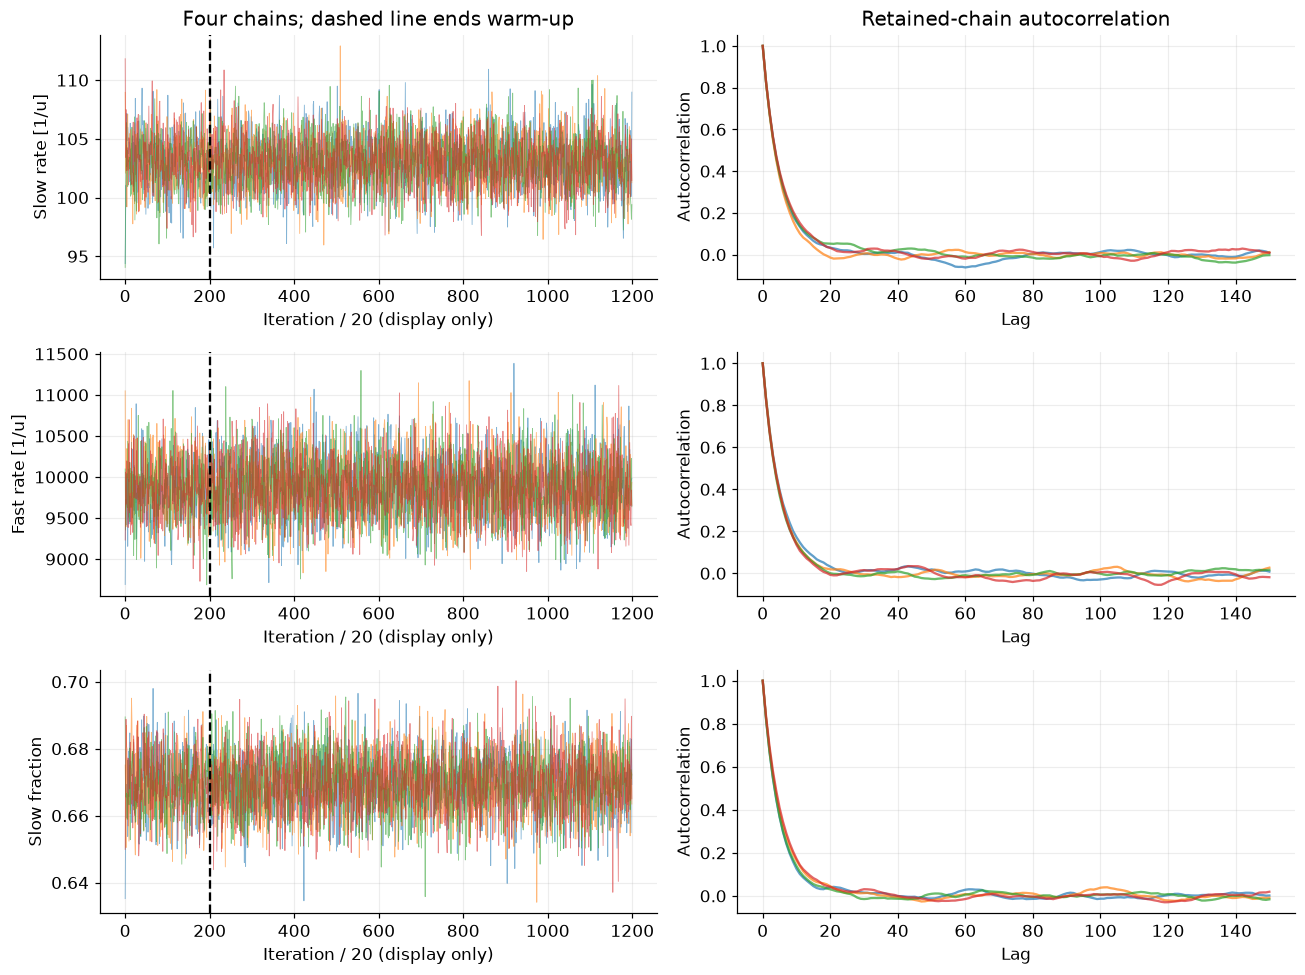

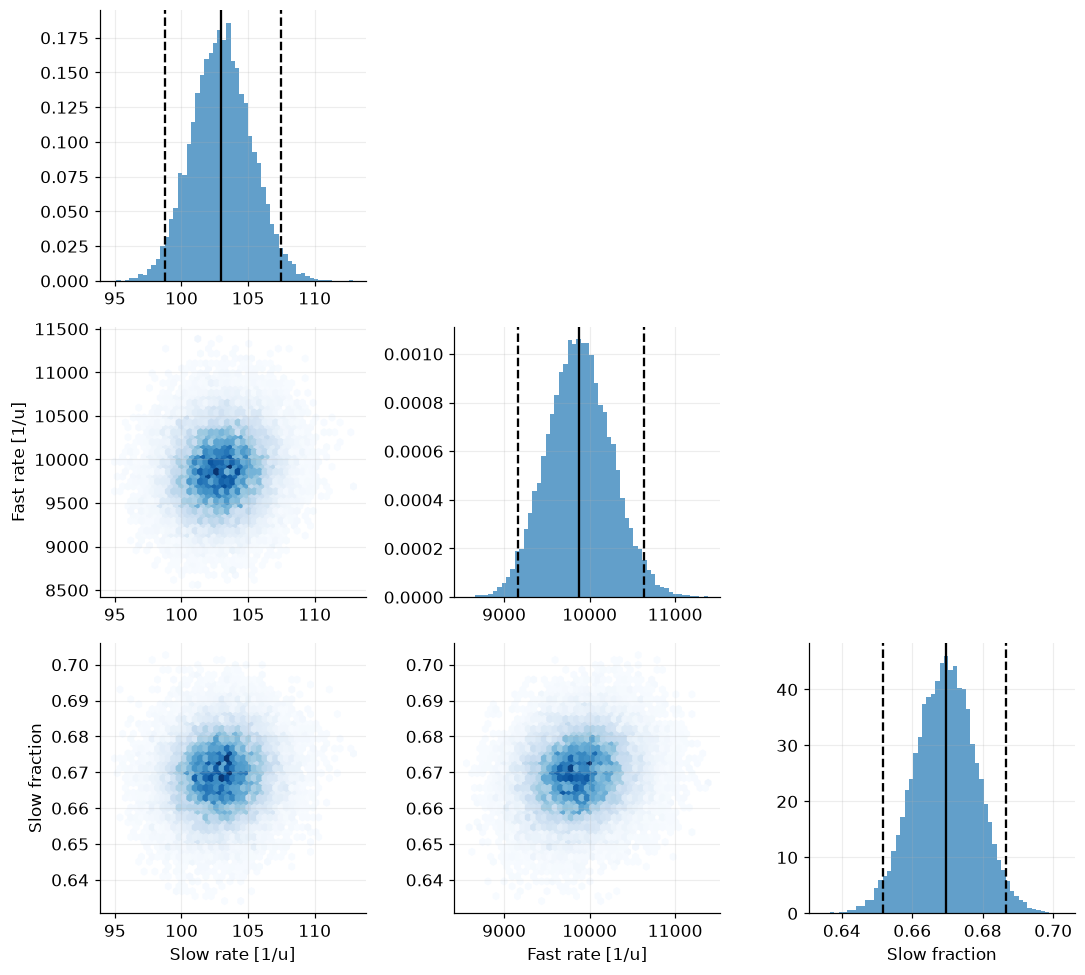

Derived parameter,Median,95% low,95% high
Slow lifetime [u],0.00970903,0.00930288,0.010129
Fast lifetime [u],0.000101285,9.40177e-05,0.000109208
Expected slow events,2209.28,2150.16,2265.66
Expected fast events,1090.72,1034.34,1149.84
Slow amplitude [events/u],227506,215986,239368
Fast amplitude [events/u],1.0769e+07,9.88659e+06,1.17207e+07


In [12]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9))
for j, name in enumerate(names2):
    for c in range(4):
        axes[j,0].plot(mix_full[c][::20,j], lw=.55, alpha=.55)
        axes[j,1].plot(ma.acf(mix_chains[c,:,j]), alpha=.7)
    axes[j,0].axvline(200, color='black', ls='--')
    axes[j,0].set(ylabel=name, xlabel='Iteration / 20 (display only)')
    axes[j,1].set(ylabel='Autocorrelation', xlabel='Lag')
axes[0,0].set_title('Four chains; dashed line ends warm-up')
axes[0,1].set_title('Retained-chain autocorrelation')
finish(fig, '09_mixture_diagnostics')

fig, axes = plt.subplots(3, 3, figsize=(10, 9))
for i in range(3):
    for j in range(3):
        ax = axes[i,j]
        if i == j:
            ax.hist(mix_flat[:,j], bins=55, density=True, alpha=.7)
            ax.axvline(q2[1,j], color='black')
            for q in [q2[0,j], q2[2,j]]:
                ax.axvline(q, color='black', ls='--')
        elif i > j:
            ax.hexbin(mix_flat[:,j], mix_flat[:,i], gridsize=45, mincnt=1, cmap='Blues')
        else:
            ax.axis('off')
        if i == 2:
            ax.set_xlabel(names2[j])
        if j == 0 and i > 0:
            ax.set_ylabel(names2[i])
finish(fig, '10_mixture_joint_posterior')

derived = np.column_stack((1/mix_flat[:,0], 1/mix_flat[:,1],
                           N2*mix_flat[:,2], N2*(1-mix_flat[:,2]),
                           N2*mix_flat[:,2]*mix_flat[:,0], N2*(1-mix_flat[:,2])*mix_flat[:,1]))
derived_names = ['Slow lifetime [u]', 'Fast lifetime [u]', 'Expected slow events',
                 'Expected fast events', 'Slow amplitude [events/u]', 'Fast amplitude [events/u]']
ma.show_table([(name, np.median(derived[:,j]), *np.quantile(derived[:,j], [.025,.975]))
               for j,name in enumerate(derived_names)],
             ['Derived parameter', 'Median', '95% low', '95% high'], [None, '.6g', '.6g', '.6g'])

**Check the cutoff, binning, and model fit.** Under the mixture, the fraction of fast
events among those passing the cut is
\[
\epsilon_f(c)=\frac{(1-w)e^{-\lambda_fc}}
{w e^{-\lambda_sc}+(1-w)e^{-\lambda_fc}}.
\]
Its posterior distribution checks the earlier tail approximation. The finite-cut
plateau, agreement between tail and global estimates, and small fitted contamination
provide complementary evidence; none makes the approximation exact.

We plot the fitted density and both components, with a 95% pointwise credible band
for the model density. We also simulate binned counts from 400 posterior draws to show
95% pointwise **posterior predictive** intervals, which include sampling variation.
Neither band is a simultaneous 95% band over the entire curve.

For a quantitative goodness-of-fit check use the multinomial deviance
$D=2\sum_{n_j>0}n_j\log[n_j/(N\widehat p_j)]$.
Many bins are sparse, so a naive chi-square approximation is avoided. We simulate
200 histograms from the fitted model, **refit all three parameters in each**, and compare
their fitted deviances with the observed value. This parametric bootstrap is conditional
on the selected bin edges and the two-exponential model, with finite simulation error.

The posterior median fast contamination above the cut is **0.00282%**, with 95% interval **[0.00130%, 0.00584%]**. This corresponds to about **0.056** fast events among the retained tail events under the fitted model. It supports treating the selected tail as approximately pure slow decay.

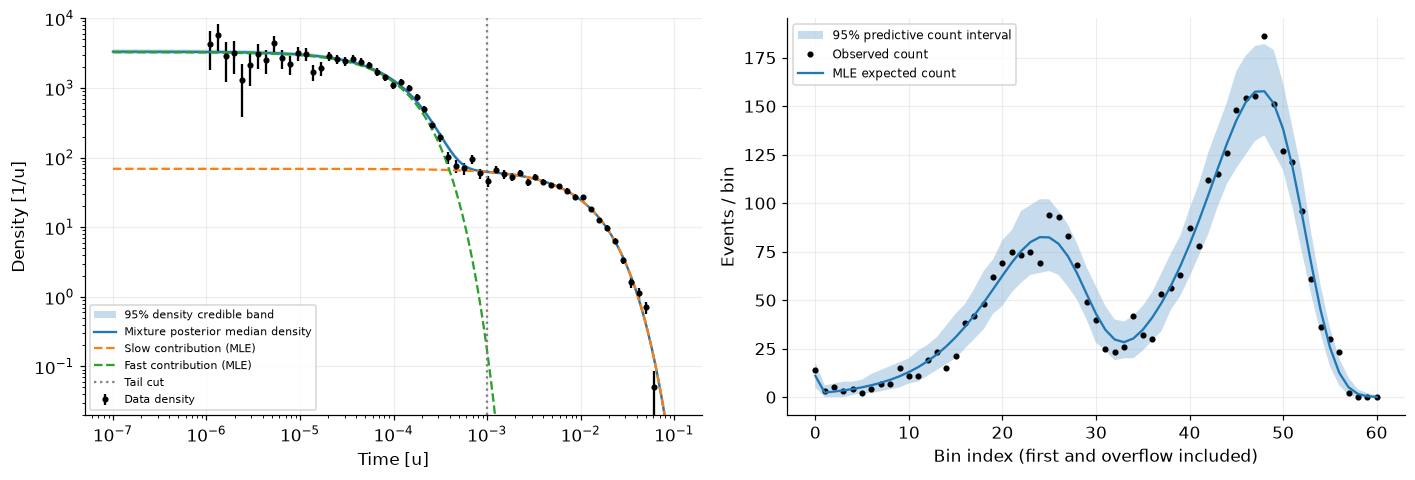

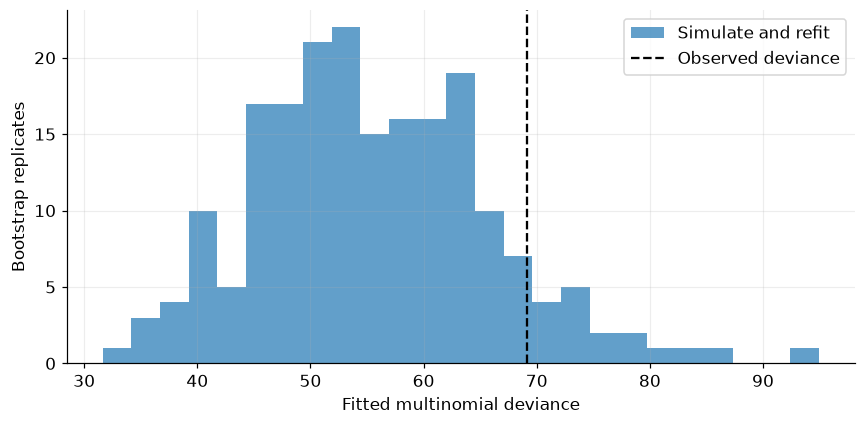

The observed deviance is **69.12** and the bootstrap tail probability is **0.095** (approximate Monte Carlo SE 0.021; 200 refitted replicates). A non-small value indicates no detected discrepancy in this binned check; it does not establish that the model is uniquely correct or exclude detector effects that were not modeled.

In [13]:
sdraw, fdraw, wdraw = mix_flat.T
fast_surv = (1-wdraw)*np.exp(-fdraw*CUT)
slow_surv = wdraw*np.exp(-sdraw*CUT)
contamination = fast_surv/(fast_surv+slow_surv)
cont_q = np.quantile(contamination, [.025,.5,.975])
display(Markdown(f'The posterior median fast contamination above the cut is '
                 f'**{100*cont_q[1]:.5f}%**, with 95% interval '
                 f'**[{100*cont_q[0]:.5f}%, {100*cont_q[2]:.5f}%]**. '
                 f'This corresponds to about **{len(tail)*cont_q[1]:.3f}** fast events '
                 'among the retained tail events under the fitted model. '
                 'It supports treating the selected tail as approximately pure slow decay.'))

pp_rng = np.random.default_rng(20261025)
chosen = pp_rng.choice(len(mix_flat), size=400, replace=False)
tplot = np.geomspace(1e-7, .1, 500)
pp_parameters = mix_flat[chosen]
ss, ff, ww = pp_parameters.T
density_draws = (ww[:,None]*ss[:,None]*np.exp(-ss[:,None]*tplot)
                 +(1-ww[:,None])*ff[:,None]*np.exp(-ff[:,None]*tplot))
density_lo, density_med, density_hi = np.quantile(density_draws, [.025,.5,.975], axis=0)
probs_draws = np.array([np.exp(ma.mixture_logprob(mix_z.reshape(-1,3)[idx], mix_edges))
                        for idx in chosen])
pred_counts = np.array([pp_rng.multinomial(N2, p/p.sum()) for p in probs_draws])
pred_lo, pred_hi = np.quantile(pred_counts, [.025,.975], axis=0)
sm, fm, wm = ma.decode(fit_log.x)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].errorbar(centers, dens, yerr=err, fmt='.', color='black', label='Data density')
axes[0].fill_between(tplot, density_lo, density_hi, alpha=.25, label='95% density credible band')
axes[0].plot(tplot, density_med, label='Mixture posterior median density')
axes[0].plot(tplot, wm*sm*np.exp(-sm*tplot), '--', label='Slow contribution (MLE)')
axes[0].plot(tplot, (1-wm)*fm*np.exp(-fm*tplot), '--', label='Fast contribution (MLE)')
axes[0].axvline(CUT, color='gray', ls=':', label='Tail cut')
axes[0].set(xscale='log', yscale='log', ylim=(.02, 1e4), xlabel='Time [u]', ylabel='Density [1/u]')
axes[0].legend(fontsize=7)
idx = np.arange(len(mix_counts))
axes[1].fill_between(idx, pred_lo, pred_hi, alpha=.25, label='95% predictive count interval')
axes[1].plot(idx, mix_counts, 'k.', label='Observed count')
axes[1].plot(idx, N2*np.exp(ma.mixture_logprob(fit_log.x, mix_edges)), label='MLE expected count')
axes[1].set(xlabel='Bin index (first and overflow included)', ylabel='Events / bin')
axes[1].legend(fontsize=8)
finish(fig, '11_global_fit_predictive')

p_hat = np.exp(ma.mixture_logprob(fit_log.x, mix_edges))
observed_deviance = ma.deviance(mix_counts, p_hat)
B = 200
boot_rng = np.random.default_rng(20261026)
boot_deviances = []
for b in range(B):
    simulated = boot_rng.multinomial(N2, p_hat/p_hat.sum())
    bf = ma.fit_mixture(edges=mix_edges, counts=simulated, start=fit_log.x, multistart=False)
    boot_deviances.append(ma.deviance(simulated, np.exp(ma.mixture_logprob(bf.x, mix_edges))))
bootstrap_p = (1 + np.count_nonzero(np.array(boot_deviances) >= observed_deviance))/(B+1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(boot_deviances, bins=25, alpha=.7, label='Simulate and refit')
ax.axvline(observed_deviance, color='black', ls='--', label='Observed deviance')
ax.set(xlabel='Fitted multinomial deviance', ylabel='Bootstrap replicates')
ax.legend()
finish(fig, '12_goodness_of_fit')
display(Markdown(f'The observed deviance is **{observed_deviance:.2f}** and the '
                 f'bootstrap tail probability is **{bootstrap_p:.3f}** '
                 f'(approximate Monte Carlo SE {np.sqrt(bootstrap_p*(1-bootstrap_p)/B):.3f}; '
                 f'{B} refitted replicates). '
                 'A non-small value indicates no detected discrepancy in this binned check; '
                 'it does not establish that the model is uniquely correct or exclude '
                 'detector effects that were not modeled.'))

## Discussion and conclusion

**Part 1.** Binning changes information, not the underlying physical distribution.
Coarse time bins broaden the rate posterior, while sufficiently fine bins reproduce the
unbinned reference. Sparse bins are handled naturally by exact multinomial/Poisson
likelihoods. Logarithmic bins redistribute resolution; they are especially useful when
the data span several scales. The resolution study distinguishes posterior SD from
repeated-experiment estimator SD and confirms the expected $N^{-1/2}$ scaling.

**Part 2.** A lower cut isolates the long-lived component only approximately. Conditioning
on that cut requires replacing $t$ by $t-c$. A tail fit supplies an initial slow rate
and component fraction; the final joint mixture fit uses the whole sample once and
propagates uncertainty to both rates and the fraction. Ordering the rates removes
label switching. Integrated bin probabilities keep logarithmic-bin fitting correctly
normalized. The unbinned comparison, cut stability, predictive plots, bootstrap check,
and MCMC diagnostics assess different possible failure modes.

**Limits of the result.** Credible intervals are conditional on the specified priors,
independence assumption, and two-exponential model. The rate prior is not universal:
its numerical bounds refer to the file's time unit. The goodness-of-fit check is finite
and binned; it does not prove the model. Systematic errors, dead time, an acquisition
window, or a background component would need additional information and a revised
likelihood. No such effects or physical units are supplied in the exercise.

**Numerical interpretation.** The primary binned MLEs are 103.021 and 9,873.59 inverse time units, compared with 103.155 and 9,879.92 for the unbinned fit. The differences (0.134 and 6.33) are small relative to the posterior SDs (2.24 and 377.18), so the chosen logarithmic binning preserves almost all relevant information here. The tail-only slow estimate, 103.645, is also consistent with the joint fit. The slow event fraction is about 0.6695, leaving about 0.3305 in the fast population.

The goodness-of-fit bootstrap probability is 0.095 (Monte Carlo SE about 0.021). The observed deviance is somewhat high within the simulated distribution, but this check does not reject the model at the conventional 5% level. Small discrepancies in sparse bins and the far tail remain worth inspecting; the result is evidence of an adequate approximation, not proof of an exact physical model. All reported parameter R-hat values are below 1.001; the smallest bulk ESS in the mixture fit exceeds 7,000.

For the simulated single exponential, two linear bins inflate posterior SD by about 22% relative to unbinned inference. The inflation is about 1.7% for 20 linear bins, 0.1% for 200 linear bins, and 0.5% for the chosen 20 logarithmic bins. Logarithmic binning happens to slightly outperform 20 linear bins for this realization; this does not imply a general ordering of these nonnested partitions. The repeated-experiment resolution slope is ?0.507, close to ?0.5.

In [14]:
display(Markdown(
    f'**Final global estimates (primary logarithmic-bin posterior):** '
    f'slow rate **{q2[1,0]:.2f} u⁻¹** '
    f'(95% CrI [{q2[0,0]:.2f}, {q2[2,0]:.2f}]); '
    f'fast rate **{q2[1,1]:.0f} u⁻¹** '
    f'(95% CrI [{q2[0,1]:.0f}, {q2[2,1]:.0f}]); '
    f'slow event fraction **{q2[1,2]:.4f}** '
    f'(95% CrI [{q2[0,2]:.4f}, {q2[2,2]:.4f}]). '
    f'The fast rate is approximately **{q2[1,1]/q2[1,0]:.1f} times** the slow rate.'))

# Save a compact, machine-readable record of the values reported above.
summary = {'n_events': N2, 'cut': CUT, 'tail_count': len(tail),
           'tail_mle': slow_mle, 'tail_ci95': tail_ci.tolist(),
           'binning_comparison': binning_rows,
           'resolution_slope': float(slope),
           'global_mle_log': ma.decode(fit_log.x).tolist(),
           'global_mle_unbinned': ma.decode(fit_raw.x).tolist(),
           'posterior_mean': mean2.tolist(), 'posterior_sd': sd2.tolist(),
           'posterior_quantiles_025_50_975': q2.tolist(),
           'diagnostics_part1': diagnostics1, 'diagnostics_mixture': mix_diag,
           'fast_contamination_quantiles': cont_q.tolist(),
           'deviance': observed_deviance, 'bootstrap_p': bootstrap_p}
Path('results_summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('All inference and convergence assertions passed. Figures and results summary saved.')

**Final global estimates (primary logarithmic-bin posterior):** slow rate **103.00 u⁻¹** (95% CrI [98.73, 107.49]); fast rate **9873 u⁻¹** (95% CrI [9157, 10636]); slow event fraction **0.6695** (95% CrI [0.6516, 0.6866]). The fast rate is approximately **95.9 times** the slow rate.

All inference and convergence assertions passed. Figures and results summary saved.


## Reproducibility and implementation notes

- `mcmc_analysis.py` contains the model-specific sampler, stable likelihoods, numerical
  quadrature, optimizer, and diagnostic routines. Read alongside the equations above.
- `mcmc_sampler.py` is the supplied generic sampler, preserved unchanged. The subclass
  overrides its proposal and acceptance methods; the original continuously adapting
  method is not used.
- Exact probabilities use `expm1` to avoid subtracting nearly equal exponentials.
  Mixtures use `logaddexp` to avoid underflow. Multinomial constants independent of
  parameters are omitted only in optimization and sampling, where they cancel.
- The original `mcmc_tools.py` remains in `provided/` as a reference and is not a runtime
  dependency. No external LaTeX installation, pandas, or seaborn is needed.
- `results_summary.json` records the reported values, and `figures/` contains the plots.
  Every inference can be regenerated by running this notebook in order.

Reference for convergence definitions: [Stan, Posterior Analysis](https://mc-stan.org/docs/reference-manual/analysis.html).
The exponential likelihoods, bin integrals, tail conditioning, and conjugate posterior
are derived explicitly in this notebook.